# Simulating the focal field of an off-axis parabolic mirror — a step-by-step method

A self-contained, reusable recipe for the **vectorial focal field** of an OAP. It
takes an arbitrary complex input field, reflects it off the real 3-D mirror (with
material Fresnel coefficients and rigid-body tilt/shift), and evaluates the field near
focus with a **Debye–Wolf** integral. The example input is a polarised Gaussian beam with an optional vortex phase; all
parameters are in the first code cell.

Pipeline:

$$
\underbrace{\text{paraboloid}}_{1}\!\to\!
\underbrace{\text{aperture}}_{2}\!\to\!
\underbrace{\text{input field}}_{3}\!\to\!
\underbrace{\hat{\mathbf e}_r}_{4}\!\to\!
\underbrace{s,p,\;r_s,r_p}_{5}\!\to\!
\underbrace{\text{focus }\mathbf F}_{6}\!\to\!
\underbrace{J_\Omega}_{7}\!\to\!
\underbrace{\varphi_\text{OPD}}_{8}\!\to\!
\underbrace{\text{Debye sum}}_{9}
$$

The focal field is
$$
\boxed{\;\mathbf E(v,w)=\iint P(k_v,k_w)\,e^{\,i(k_v v+k_w w)}\,dk_v\,dk_w\;},\qquad
P\propto \mathbf E_r\,\sqrt{J_\Omega}\,e^{\,i\varphi_\text{OPD}} .
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

# ================= parameters (edit these) =================
F     = 7.5e-3          # PARENT focal length [m]
LAM   = 1030e-9         # wavelength [m]
K     = 2*np.pi/LAM
APER  = 0.5*25.4e-3     # clear aperture diameter [m]
E_I   = np.array([0., 0., -1.])         # input propagation direction (see step 3)

# input field (step 3): Gaussian, 1/e amplitude radius W0, vortex of charge ELL
W0    = 2e-3            # [m]  (np.inf -> uniform illumination)
ELL   = 1               # topological charge (0 -> plain Gaussian)
POL   = np.array([1., 0., 0.])          # input polarisation

# mirror material: complex refractive index (set for 'perfect' below)
N_MAT   = 0.26 + 6.82j        # gold near 1030 nm (approx). Try 0.04+7.5j for silver.
PERFECT = False               # True -> ideal conductor (rs=-1, rp=+1)

# off-axis geometry: 90-deg fold uses the parent section centred at rho0 = 2f
XC = -2*F                     # off-axis centre on the parent (-> +x fold)
ZC = XC**2/(4*F)              # chief mirror height (= f)
PIVOT = np.array([XC, 0., 0.])   # mount's rotation/shift reference point (physical
                                  # mounting point of the OAP, NOT a point on the
                                  # mirror surface itself)

# rigid-body placement (step 1): independent tilts about the lab x,y,z axes
# (R = Rz@Ry@Rx), applied about PIVOT, plus a rigid shift move the MIRROR only —
# the input beam grid stays fixed and centred on XC.
TILT_DEG = np.array([0.03, 0.0, 0.0])   # mirror tilt about (x,y,z) [deg]
SHIFT    = np.array([0e-3, 0e-3, 0e-3])   # rigid shift [m]

# observation (step 9)
DEFOCUS    = 0.0          # axial (u) shift of the observation plane from the ref. focus [m]
Lout, Nout = 20e-6, 200   # focal window size [m] and pixels

RFL = F + XC**2/(4*F)     # reflected focal length (chief-ray hit point -> focus)
print(f"reflected focal length={RFL*1e3:.2f} mm  aperture={APER*1e3:.2f} mm  "
      f"material={'perfect' if PERFECT else N_MAT}")

reflected focal length=15.00 mm  aperture=12.70 mm  material=(0.26+6.82j)


## Step 1 — Paraboloid, gradient (normal), tilt & shift

Parent paraboloid and its normal from the gradient of $F=z-\dfrac{x^2+y^2}{4f}$:
$$
z_p=\frac{x_p^2+y_p^2}{4f},\qquad
\hat{\mathbf n}_p=\frac{\nabla F}{|\nabla F|}
=\frac{(-x_p/2f,\,-y_p/2f,\,1)}{\sqrt{1+(x_p^2+y_p^2)/4f^2}} .
$$
Tilt/shift is a rigid transform of the **mirror only** (the input beam grid stays fixed,
centred on $X_C$), pivoted about the mount's physical reference point
$\mathbf p_0=(X_C,0,0)$ rather than the paraboloid's own vertex:
$$
\mathbf r_\text{lab}=R\,(\mathbf r_p-\mathbf p_0)+\mathbf p_0+\mathbf t,\qquad
\hat{\mathbf n}_\text{lab}=R\,\hat{\mathbf n}_p,
\qquad R=R_z(\theta_z)\,R_y(\theta_y)\,R_x(\theta_x) .
$$
The three tilt angles (`TILT_DEG`), the shift `SHIFT`, and the pivot `PIVOT` are all
independent — set any combination to move the mirror about its mount while the beam
stays put.


R =
 [[ 1.00e+00  0.00e+00  0.00e+00]
 [ 0.00e+00  1.00e+00 -5.24e-04]
 [ 0.00e+00  5.24e-04  1.00e+00]]
pivot p0 = [-15.   0.   0.] mm   shift t = [0. 0. 0.] mm
effective translation T (r_lab = R@r_p + T) = [0. 0. 0.] mm


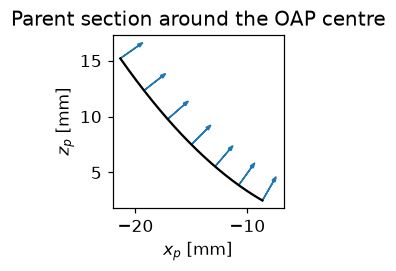

In [2]:
def rotation_matrix(axis, ang):
    a = np.asarray(axis, float); a = a/np.linalg.norm(a)
    Kx = np.array([[0,-a[2],a[1]],[a[2],0,-a[0]],[-a[1],a[0],0]])
    return np.eye(3) + np.sin(ang)*Kx + (1-np.cos(ang))*(Kx@Kx)

def z_parent(xp, yp): return (xp**2+yp**2)/(4*F)

def normal_parent(xp, yp):
    n = np.stack([-xp/(2*F), -yp/(2*F), np.ones_like(np.asarray(xp,float))], -1)
    return n/np.linalg.norm(n, axis=-1, keepdims=True)

Rx = rotation_matrix((1,0,0), np.deg2rad(TILT_DEG[0]))
Ry = rotation_matrix((0,1,0), np.deg2rad(TILT_DEG[1]))
Rz = rotation_matrix((0,0,1), np.deg2rad(TILT_DEG[2]))
R = Rz @ Ry @ Rx
T = PIVOT - R @ PIVOT + SHIFT   # rotate about PIVOT, then apply SHIFT: r_lab = R@r_p + T
print("R =\n", np.round(R,6))
print("pivot p0 =", PIVOT*1e3, "mm   shift t =", SHIFT*1e3, "mm")
print("effective translation T (r_lab = R@r_p + T) =", np.round(T*1e3,4), "mm")

# quick look at the parent section + a few normals (in the x-z meridian)
xx = np.linspace(XC-APER/2, XC+APER/2, 200)
plt.figure(figsize=(5,2.6))
plt.plot(xx*1e3, z_parent(xx,0)*1e3, 'k')
for x0 in np.linspace(XC-APER/2, XC+APER/2, 7):
    n = normal_parent(x0,0.); z_arrow = z_parent(x0,0.)
    plt.arrow(x0*1e3, z_arrow*1e3, n[0]*2, n[2]*2, head_width=0.3, color='C0')
plt.gca().set_aspect('equal'); plt.xlabel('$x_p$ [mm]'); plt.ylabel('$z_p$ [mm]')
plt.title('Parent section around the OAP centre'); plt.tight_layout(); plt.show()


## Step 2 — Aperture mask: a circle in the mirror's local y–z plane

The clear aperture is a circle of diameter `APER` defined in the mirror **body**: seen
along the mirror's *local* (pre-tilt) fold (+x) axis, i.e. a circle in the mirror's own
**local $y_p$–$z_p$ plane** centred on the chief-ray hit point. It therefore moves
rigidly with the mirror under any `TILT_DEG`/`SHIFT`, like a real aperture stop. We
trace the fixed input ray grid (centred on $X_C$) to the surface (closed-form
quadratic below) and keep the mirror points whose *local* $(y_p,z_p)$ fall in the circle:
$$
(y_p-y_0)^2+(z_p-z_0)^2\le (D/2)^2 .
$$
The same `aperture_mask` is used in all three notebooks. Because the surface is inclined
to the input beam, the circle maps to a foreshortened footprint on the input plane.

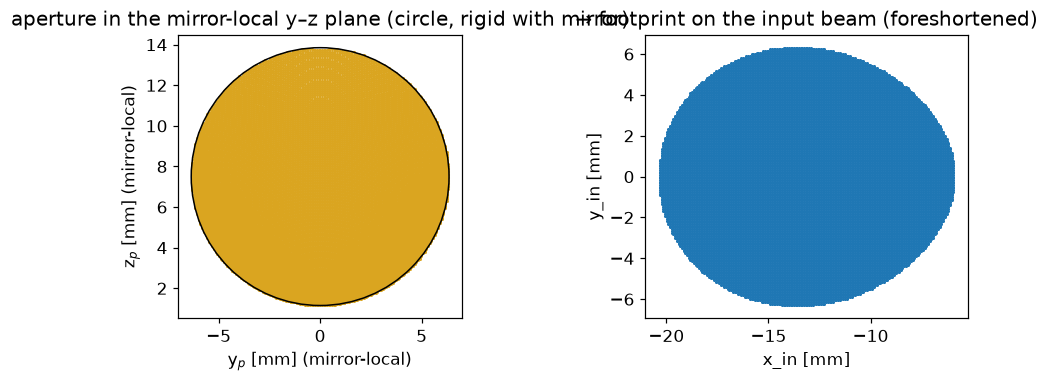

20767 rays inside the aperture


In [3]:
def intersect(Xin, Yin, zin, R, t):
    """closed-form first intersection of the E_I rays with the transformed paraboloid"""
    Rt = R.T; d = Rt @ E_I
    rin = np.stack([Xin, Yin, np.full_like(Xin, zin)], -1)
    a = (rin - t) @ Rt.T
    ax, ay, az = a[...,0], a[...,1], a[...,2]; dx, dy, dz = d
    A = (dx**2+dy**2)/(4*F); B = 2*(ax*dx+ay*dy)/(4*F) - dz; C = (ax**2+ay**2)/(4*F) - az
    # cancellation-free roots: s1 = C/q, s2 = q/A. The naive (-B+disc)/(2A) loses all
    # precision when A -> 0 (tiny tilts); this form degrades smoothly to s = -C/B.
    disc = np.sqrt(np.maximum(B**2-4*A*C, 0.0))
    q = -0.5*(B + np.where(B >= 0, disc, -disc))
    s1 = C/q
    s2 = q/A if A != 0 else np.full_like(s1, np.inf)
    s = np.where((s1>0) & ((s1<s2)|(s2<=0)), s1, s2)          # first hit
    r_p = a + s[...,None]*d
    return r_p[...,0], r_p[...,1], rin + s[...,None]*E_I

def aperture_mask(xp, yp, D=APER, y0=0.0, z0=ZC):
    """Clear aperture (same definition in all notebooks): a circle of diameter D in
    the mirror-local y_p-z_p plane, i.e. seen along the local fold axis, centred on
    the chief-ray hit point (y0, z0). Takes parent coordinates, so it is body-fixed
    and moves rigidly with the mirror under any tilt/shift."""
    zp = (xp**2 + yp**2)/(4*F)
    return ((yp-y0)**2 + (zp-z0)**2 <= (D/2)**2) & (xp*XC > 0)   # the XC side of the parent

pix = 260
Lp  = 1.7*APER
xi  = (np.arange(pix)-pix/2)*(Lp/pix)
Xin = XC + np.meshgrid(xi, xi, indexing='xy')[0]
Yin =      np.meshgrid(xi, xi, indexing='xy')[1]
zin = 0.05
xp, yp, r_m = intersect(Xin, Yin, zin, R, T)
zp = z_parent(xp, yp)                        # local (mirror-body) z of each hit point

y0, z0 = 0.0, ZC                             # aperture centre in the mirror's LOCAL y-z
APMASK = aperture_mask(xp, yp, y0=y0, z0=z0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ax[0].scatter(yp[APMASK]*1e3, zp[APMASK]*1e3, s=1, c='goldenrod')
ax[0].add_patch(plt.Circle((y0*1e3, z0*1e3), APER/2*1e3, fill=False, color='k'))
ax[0].set_aspect('equal'); ax[0].set_xlabel('y$_p$ [mm] (mirror-local)'); ax[0].set_ylabel('z$_p$ [mm] (mirror-local)')
ax[0].set_title('aperture in the mirror-local y–z plane (circle, rigid with mirror)')
ax[1].scatter(Xin[APMASK]*1e3, Yin[APMASK]*1e3, s=1, c='C0')
ax[1].set_aspect('equal'); ax[1].set_xlabel('x_in [mm]'); ax[1].set_ylabel('y_in [mm]')
ax[1].set_title('→ footprint on the input beam (foreshortened)')
plt.tight_layout(); plt.show()
print(f"{APMASK.sum()} rays inside the aperture")

## Step 3 — Input field

$$
E_\text{in}(x,y)=A(x,y)\,e^{\,i\phi(x,y)},\qquad
A=e^{-r^2/w_0^2},\quad \phi=\ell\,\arg\!\big[(x-x_c)+i(y-y_c)\big],
$$
polarised along `POL`, centred on the off-axis footprint $(x_c,y_c)=(X_C,0)$;
$w_0$ = `W0`, $\ell$ = `ELL`. Any other complex `E_in(x,y)` can be used here.

**What `E_in` means.** It is the field in a plane just in front of the mirror, carried
to the surface along the fixed direction $\hat{\mathbf e}_i$ (`E_I`): each ray is
sampled at its own $(x,y)$ and travels exactly along $\hat{\mathbf e}_i$. Phase gradients
of `E_in` therefore enter only as phase, not as ray directions. This is valid for a
beam that is locally close to collimated along $\hat{\mathbf e}_i$. A field with strong
phase gradients (e.g. after an SLM and a lens) must first be propagated to the mirror
(e.g. angular-spectrum method), and is only usable if it is still nearly collimated there.

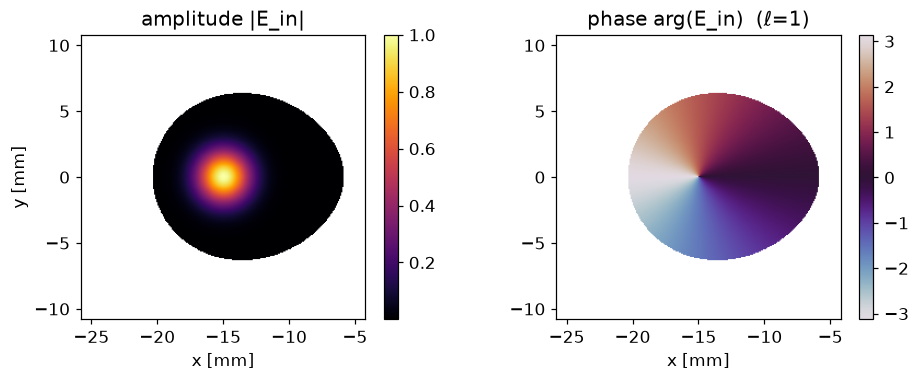

In [4]:
r2 = (Xin-XC)**2 + Yin**2
E_in = np.exp(-r2/W0**2) * np.exp(1j*ELL*np.arctan2(Yin, Xin-XC))
E_in = E_in.astype(complex)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
extf = [(XC-Lp/2)*1e3,(XC+Lp/2)*1e3,-Lp/2*1e3,Lp/2*1e3]
im0 = ax[0].imshow(np.where(APMASK, np.abs(E_in), np.nan), origin='lower', extent=extf, cmap='inferno')
ax[0].set_title('amplitude |E_in|'); ax[0].set_xlabel('x [mm]'); ax[0].set_ylabel('y [mm]')
plt.colorbar(im0, ax=ax[0], fraction=.046)
im1 = ax[1].imshow(np.where(APMASK, np.angle(E_in), np.nan), origin='lower',
                   extent=extf, cmap='twilight')
ax[1].set_title(f'phase arg(E_in)  (ℓ={ELL})'); ax[1].set_xlabel('x [mm]')
plt.colorbar(im1, ax=ax[1], fraction=.046)
plt.tight_layout(); plt.show()

## Step 4 — Reflected ray directions

Purely geometric (independent of material) — Householder reflection of the incident
direction about the local normal:
$$
\hat{\mathbf e}_r=\hat{\mathbf e}_i-2(\hat{\mathbf e}_i\!\cdot\!\hat{\mathbf n}_\text{lab})\,\hat{\mathbf n}_\text{lab},\qquad \|\hat{\mathbf e}_r\|=1 .
$$

In [5]:
n_lab = normal_parent(xp, yp) @ R.T
e_r = E_I - 2*np.sum(E_I*n_lab, -1, keepdims=True)*n_lab
u0 = e_r[APMASK].mean(0); u0 /= np.linalg.norm(u0)
cone = np.degrees(np.arccos(np.clip(e_r[APMASK] @ u0, -1, 1)))
print("mean reflected direction over aperture:", np.round(u0, 3))
print(f"cone half-angle about the mean ray: up to {cone.max():.1f} deg (sin = {np.sin(np.radians(cone.max())):.2f}); "
      f"nominal NA sin(atan(D/2RFL)) = {np.sin(np.arctan(APER/2/RFL)):.2f}")
print("max ||e_r|-1| =", np.abs(np.linalg.norm(e_r,axis=-1)-1)[APMASK].max())

mean reflected direction over aperture: [ 0.992 -0.001  0.127]
cone half-angle about the mean ray: up to 39.6 deg (sin = 0.64); nominal NA sin(atan(D/2RFL)) = 0.39
max ||e_r|-1| = 6.661338147750939e-16


## Step 5 — Local s/p basis and material (Fresnel)

Decompose into $s$ (⊥ plane of incidence) and $p$ (in it), apply the **material**
Fresnel coefficients, and keep the reflected field transverse to $\hat{\mathbf e}_r$:
$$
\hat{\mathbf s}=\frac{\hat{\mathbf e}_i\times\hat{\mathbf n}}{|\hat{\mathbf e}_i\times\hat{\mathbf n}|},\;\;
\hat{\mathbf p}_i=\hat{\mathbf e}_i\times\hat{\mathbf s},\;\;
\hat{\mathbf p}_r=\hat{\mathbf e}_r\times\hat{\mathbf s},\qquad
\boxed{\mathbf E_r=r_s(\mathbf E_i\!\cdot\!\hat{\mathbf s})\hat{\mathbf s}+r_p(\mathbf E_i\!\cdot\!\hat{\mathbf p}_i)\hat{\mathbf p}_r}
$$
$$
r_s=\frac{\cos\theta_i-\tilde n\cos\theta_t}{\cos\theta_i+\tilde n\cos\theta_t},\qquad
r_p=\frac{\tilde n\cos\theta_i-\cos\theta_t}{\tilde n\cos\theta_i+\cos\theta_t},\qquad
\cos\theta_t=\sqrt{1-\tilde n^{-2}\sin^2\theta_i}.
$$
Choosing the complex index $\tilde n$ selects the material; $r_s=-1,r_p=+1$ is the
perfect conductor.

In [6]:
def fresnel_rs_rp(cos_i, n2):
    cos_t = np.sqrt(1 - (1/n2)**2*np.clip(1-cos_i**2,0,1) + 0j)
    cos_t = np.where(cos_t.imag < 0, -cos_t, cos_t)
    rs = (cos_i - n2*cos_t)/(cos_i + n2*cos_t)
    rp = (n2*cos_i - cos_t)/(n2*cos_i + cos_t)
    return rs, rp

def reflect_field(E, n):
    s = np.cross(np.broadcast_to(E_I, n.shape), n)
    sm = np.linalg.norm(s, axis=-1, keepdims=True)
    s = np.where(sm > 1e-12, s/np.where(sm>0,sm,1.), np.array([0.,1.,0.]))
    er = E_I - 2*np.sum(E_I*n, -1, keepdims=True)*n
    p_i = np.cross(np.broadcast_to(E_I, n.shape), s); p_r = np.cross(er, s)
    cos_i = np.abs(np.sum(E_I*n, -1))
    if PERFECT:
        rs, rp = -np.ones_like(cos_i)+0j, np.ones_like(cos_i)+0j
    else:
        rs, rp = fresnel_rs_rp(cos_i, N_MAT)
    Es = np.sum(E*s, -1, keepdims=True); Ep = np.sum(E*p_i, -1, keepdims=True)
    return rs[...,None]*Es*s + rp[...,None]*Ep*p_r

E_i_vec = E_in[...,None]*POL
E_r_vec = reflect_field(E_i_vec, n_lab)
inc = np.degrees(np.arccos(np.abs(np.sum(E_I*n_lab,-1))))
print(f"incidence angles over aperture: {inc[APMASK].min():.1f}-{inc[APMASK].max():.1f} "
      f"deg (mean {inc[APMASK].mean():.1f})")
if not PERFECT:
    rs,rp = fresnel_rs_rp(np.cos(np.deg2rad(inc[APMASK].mean())), N_MAT)
    print(f"at mean incidence: R_s={abs(rs)**2:.4f} R_p={abs(rp)**2:.4f} "
          f"phase split={np.degrees(np.angle(rp)-np.angle(rs))-180:+.1f} deg")

trans_error = np.abs(
    np.sum(E_r_vec * e_r, axis=-1)
)

print(trans_error[APMASK].max())

incidence angles over aperture: 21.6-53.6 deg (mean 41.4)
at mean incidence: R_s=0.9838 R_p=0.9713 phase split=+9.7 deg
2.1103821920200808e-17


## Step 6 — Reference focus from least-squares on the rays (+ geometry & spot diagram)

A tilted OAP has no exact stigmatic focus, so take the point closest to all reflected
ray lines:
$$
\Big[\textstyle\sum_i(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})\Big]\mathbf F
=\sum_i(\mathbb 1-\hat{\mathbf e}_{r,i}\hat{\mathbf e}_{r,i}^{\top})\,\mathbf r_{m,i}.
$$
Below: a few traced rays, and a **spot diagram** (where the rays pierce the focal plane).

least-squares focus F = [-0.    -0.011  7.5  ] mm


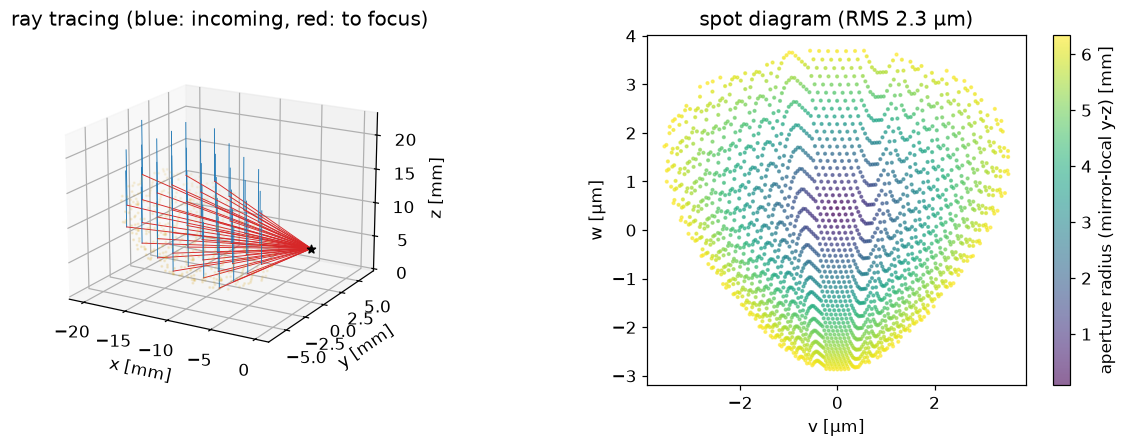

In [7]:
er_in, rm_in = e_r[APMASK], r_m[APMASK]
Pm = np.eye(3) - er_in[:,:,None]*er_in[:,None,:]
Fpt = np.linalg.solve(Pm.sum(0), np.einsum('nij,nj->i', Pm, rm_in))
print("least-squares focus F =", np.round(Fpt*1e3,3), "mm")

# output basis: mean ray
weights = np.abs(E_in[APMASK])**2
u = np.sum(weights[:, None] * er_in, axis=0)
u /= np.linalg.norm(u)
# u = er_in.mean(0); u/=np.linalg.norm(u)
ref = np.array([0,0,1.]) if abs(u[2])<0.9 else np.array([1.,0,0])
vv = ref-np.dot(ref,u)*u; vv/=np.linalg.norm(vv); ww = np.cross(u,vv)
kv = K*(e_r@vv); kw = K*(e_r@ww); ku = K*(e_r@u)   # ray wavevectors on (u, vv, ww)

fig = plt.figure(figsize=(11,4.2))
ax = fig.add_subplot(1,2,1, projection='3d')
sub = np.zeros_like(APMASK); sub[::22,::22] = True; sub &= APMASK
rm_s, er_s = r_m[sub], e_r[sub]
for rm0, er0 in zip(rm_s, er_s):
    top = rm0 + np.array([0,0,1.])*8e-3
    ax.plot([top[0]*1e3,rm0[0]*1e3],[top[1]*1e3,rm0[1]*1e3],[top[2]*1e3,rm0[2]*1e3],'C0',lw=.6)
    sfoc = np.dot(Fpt-rm0, er0)
    hit = rm0 + sfoc*er0
    ax.plot([rm0[0]*1e3,hit[0]*1e3],[rm0[1]*1e3,hit[1]*1e3],[rm0[2]*1e3,hit[2]*1e3],'C3',lw=.6)
ax.scatter(r_m[...,0][APMASK][::40]*1e3, r_m[...,1][APMASK][::40]*1e3,
           r_m[...,2][APMASK][::40]*1e3, s=1, c='goldenrod', alpha=.4)
ax.scatter([Fpt[0]*1e3],[Fpt[1]*1e3],[Fpt[2]*1e3], c='k', s=30, marker='*')
ax.set_xlabel('x [mm]'); ax.set_ylabel('y [mm]'); ax.set_zlabel('z [mm]')
ax.set_title('ray tracing (blue: incoming, red: to focus)'); ax.view_init(18,-60)

ax2 = fig.add_subplot(1,2,2)
sfoc = np.sum((Fpt-rm_in)*u,-1)/np.sum(er_in*u,-1)
hit = rm_in + sfoc[:,None]*er_in
sv = (hit-Fpt)@vv; sw = (hit-Fpt)@ww
# distance of each ray from the aperture centre (y0, z0) in the mirror's LOCAL y-z plane
aper_r = np.sqrt((yp[APMASK]-y0)**2 + (zp[APMASK]-z0)**2)
sca = ax2.scatter(sv[::9]*1e6, sw[::9]*1e6, s=3, alpha=.6,
                   c=aper_r[::9]*1e3, cmap='viridis')
cb = plt.colorbar(sca, ax=ax2, fraction=.046)
cb.set_label('aperture radius (mirror-local y-z) [mm]')
ax2.set_aspect('equal'); ax2.set_xlabel('v [µm]'); ax2.set_ylabel('w [µm]')
ax2.set_title(f'spot diagram (RMS {np.sqrt((sv**2+sw**2).mean())*1e6:.1f} µm)')
plt.tight_layout(); plt.show()

## Step 7 — Solid-angle Jacobian $J_\Omega$ (numerically)

Each input area element $dx\,dy$ maps to a patch on the direction sphere. Its area is
$$
\boxed{\,J_\Omega=\Big|\dfrac{\partial\hat{\mathbf e}_r}{\partial x}\times\dfrac{\partial\hat{\mathbf e}_r}{\partial y}\Big|\,}
=\frac{d\Omega}{dx\,dy},
$$
computed by finite-differencing $\hat{\mathbf e}_r(x,y)$. Energy conservation makes the
Debye amplitude weight $\sqrt{J_\Omega}$ (this single factor already contains both the
apodisation and the solid-angle Jacobian). Control: on the parent it equals
$\cos^4(\theta/2)/f^2$.

control  J_Ω(numeric)/[cos^4(θ/2)/f^2] : mean=1.0000 scatter=4.4e-04  (analytic form is exact only for the aligned mirror)


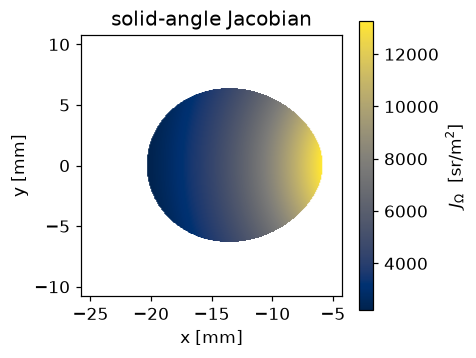

In [8]:
de_dx = np.gradient(e_r, xi, axis=1)      # ∂e_r/∂x  (input-plane coords)
de_dy = np.gradient(e_r, xi, axis=0)      # ∂e_r/∂y
J_Omega = np.linalg.norm(np.cross(de_dx, de_dy), axis=-1)
weight = np.sqrt(np.maximum(J_Omega, 0.0))

cth = e_r[...,2]
J_anal = ((1+cth)/2)**2 / F**2
ratio = (J_Omega/J_anal)[APMASK]
print(f"control  J_Ω(numeric)/[cos^4(θ/2)/f^2] : mean={ratio.mean():.4f} "
      f"scatter={ratio.std()/ratio.mean():.1e}  (analytic form is exact only for the aligned mirror)")

plt.figure(figsize=(4.4,3.6))
im = plt.imshow(np.where(APMASK, J_Omega, np.nan), origin='lower', extent=extf, cmap='cividis')
plt.colorbar(im, label='$J_\\Omega$  [sr/m$^2$]'); plt.xlabel('x [mm]'); plt.ylabel('y [mm]')
plt.title('solid-angle Jacobian'); plt.tight_layout(); plt.show()

## Step 8 — Optical path difference and the wavefront

Along each ray, the path to the focal reference plane through $\mathbf F$ is
$$
L=(\mathbf r_m-\mathbf p_\text{ref})\!\cdot\!\hat{\mathbf e}_i+\hat{\mathbf e}_r\!\cdot\!(\mathbf F-\mathbf r_m),\qquad
\varphi_\text{OPD}=k\,(L-\langle L\rangle).
$$
It is zero for the aligned mirror; any tilt/shift appears here as the wavefront
aberration. Part of $\varphi_\text{OPD}$ only moves the spot: piston and the terms
linear in $(k_v,k_w,k_u)$ (a shift of the observation point by $(\delta v,\delta w,\delta u)$
adds exactly $k_v\delta v+k_w\delta w+k_u\delta u$). `wavefront_stats` removes them by a
least-squares fit weighted by $|E_\text{in}|^2 J_\Omega$ and reports, from the residual
$\varphi_\text{res}$,
$$
\sigma=\sqrt{\langle\varphi_\text{res}^2\rangle_{a^2}}\,/\,2\pi,\qquad
S=\frac{\big|\sum a\,e^{i\varphi_\text{res}}\big|^2}{\big(\sum a\big)^2},\qquad a=|E_\text{in}|\sqrt{J_\Omega},
$$
i.e. the RMS wavefront (waves) and the Strehl ratio as peak intensity at the best point
over the unaberrated peak (scalar). The same function is used in all notebooks.
For non-uniform illumination $S\approx e^{-(2\pi\sigma)^2}$ holds only roughly, because $S$
weights by amplitude and $\sigma$ by intensity.

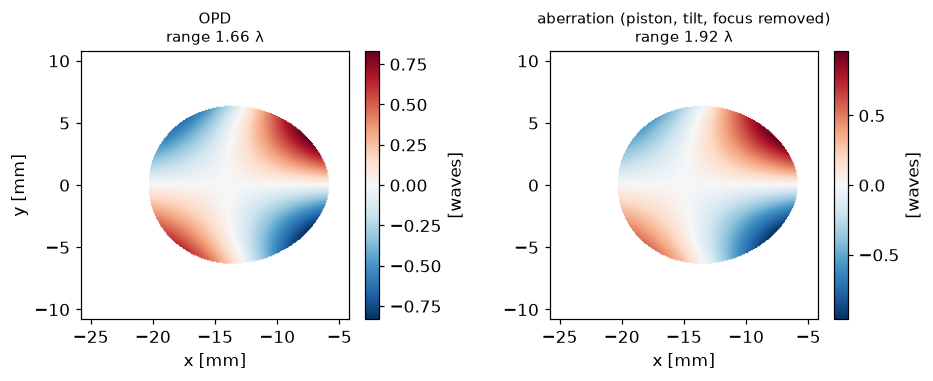

RMS wavefront = 0.034 λ   Strehl = 0.851   PtV = 1.92 λ
best point relative to the reference focus (dv, dw, du) = [-0.003  0.338 -0.015] µm


In [9]:
def wavefront_stats(phi, amp, kv, kw, ku):
    """Wavefront statistics (same definition in all notebooks).

    phi : OPD phase of each ray [rad];  amp : real ray amplitude |E_in|*sqrt(J)
    kv, kw, ku : ray wavevector on the output basis.

    Moving the observation point by (dv, dw, du) multiplies each plane wave by
    exp(i(kv dv + kw dw + ku du)), so piston and the parts of phi linear in
    (kv, kw, ku) only move the spot (pointing and focus shift), they do not blur it.
    They are removed by a least-squares fit weighted by amp**2; what is left is the
    aberration.

    rms    : amp**2-weighted RMS of the residual [waves]
    strehl : |sum amp e^{i res}|^2 / (sum amp)^2, the peak intensity at the best
             (shifted) point over the unaberrated peak (scalar, polarisation ignored)
    ptv    : peak-to-valley of the residual [waves]
    shift  : (dv, dw, du) of that best point from the reference focus [m]
    """
    k0 = np.sqrt(kv**2 + kw**2 + ku**2).mean()
    M = np.stack([np.ones_like(kv), kv/k0, kw/k0, (ku - ku.mean())/k0], -1)
    sw = amp/np.sqrt(np.sum(amp**2))
    c = np.linalg.lstsq(M*sw[:, None], phi*sw, rcond=None)[0]
    res = phi - M @ c
    rms = np.sqrt(np.sum(amp**2*res**2)/np.sum(amp**2))/(2*np.pi)
    strehl = np.abs(np.sum(amp*np.exp(1j*res)))**2/np.sum(amp)**2
    ptv = (res.max() - res.min())/(2*np.pi)
    return dict(rms=rms, strehl=strehl, ptv=ptv, shift=-c[1:]/k0, residual=res)

L = np.sum((r_m-np.array([0,0,zin]))*E_I,-1) + np.sum(e_r*(Fpt-r_m),-1)
phi = K*(L - L[APMASK].mean())
st = wavefront_stats(phi[APMASK], np.abs(E_in[APMASK])*weight[APMASK],
                     kv[APMASK], kw[APMASK], ku[APMASK])
Wraw = np.where(APMASK, phi/(2*np.pi), np.nan)
Wres = np.full(phi.shape, np.nan); Wres[APMASK] = st['residual']/(2*np.pi)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a_, Wm, ttl in [(ax[0], Wraw, 'OPD'), (ax[1], Wres, 'aberration (piston, tilt, focus removed)')]:
    lim = np.nanmax(np.abs(Wm))
    im = a_.imshow(Wm, origin='lower', extent=extf, cmap='RdBu_r', vmin=-lim, vmax=lim)
    plt.colorbar(im, ax=a_, fraction=.046, label='[waves]')
    a_.set_title(f'{ttl}\nrange {np.nanmax(Wm)-np.nanmin(Wm):.2f} λ', fontsize=10); a_.set_xlabel('x [mm]')
ax[0].set_ylabel('y [mm]'); plt.tight_layout(); plt.show()
print(f"RMS wavefront = {st['rms']:.3f} λ   Strehl = {st['strehl']:.3f}   PtV = {st['ptv']:.2f} λ")
print("best point relative to the reference focus (dv, dw, du) =", np.round(st['shift']*1e6, 3), "µm")

## Step 9 — Debye integral: focal field and its components

Each Cartesian component transforms independently (scalar kernel):
$$
E_{x,y,z}(v,w;\delta u)=\sum_{\text{aperture}}\big[\mathbf E_r\big]_{x,y,z}\,\sqrt{J_\Omega}\,
e^{i\varphi_\text{OPD}}\,e^{\,i k_u\delta u}\,
e^{\,i(k_v v+k_w w)}\,\frac{-i}{\lambda}\,\Delta A,\qquad
I=|E_x|^2+|E_y|^2+|E_z|^2,
$$
with $k_v=k\,\hat{\mathbf e}_r\!\cdot\!\hat{\mathbf v}$, $k_w=k\,\hat{\mathbf e}_r\!\cdot\!\hat{\mathbf w}$,
$k_u=k\,\hat{\mathbf e}_r\!\cdot\!\hat{\mathbf u}$ on the output basis
$(\hat{\mathbf u},\hat{\mathbf v},\hat{\mathbf w})$ from step 6. $\delta u$ (`DEFOCUS`)
shifts the observation plane along the optical axis away from the reference focus —
positive moves it further from the mirror.

The prefactor $-i/\lambda$ (Debye–Wolf, energy-conserving weight $\sqrt{J_\Omega}$) makes $\mathbf E$ absolute: with $E_\text{in}$ in V/m the focal field is in V/m, up to the constant phase $e^{ikf}$ that is dropped.

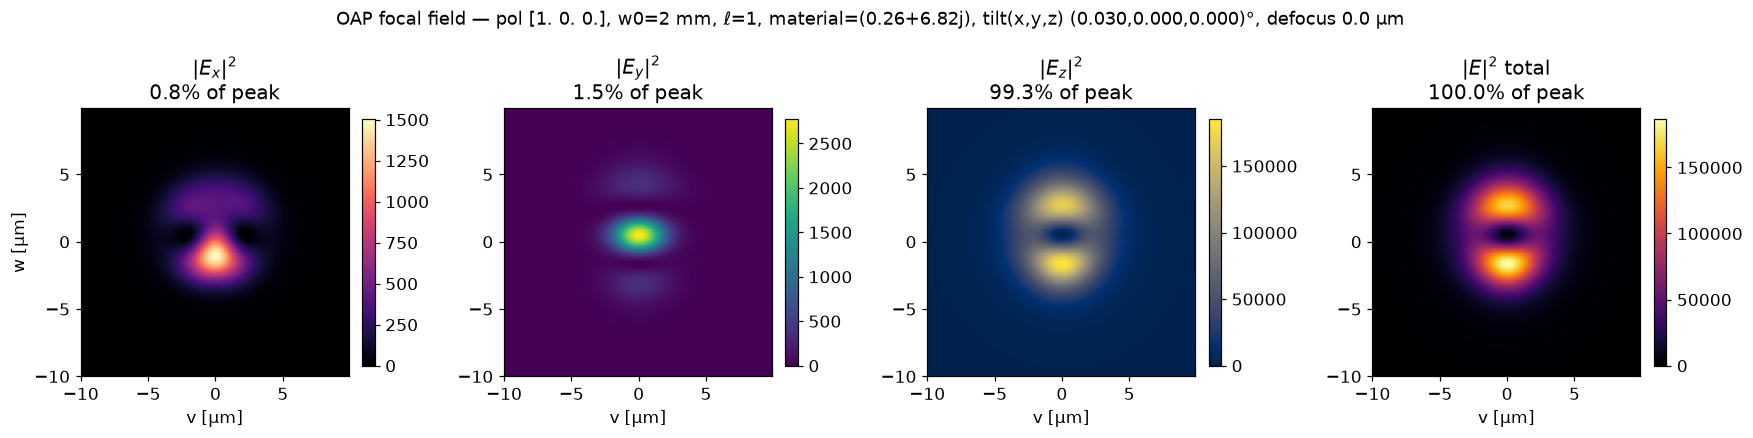

component power split  x:0.005  y:0.005  z:0.991


In [10]:
dA = (Lp/pix)**2
m = APMASK
# Debye-Wolf sum with the -i/lambda prefactor (absolute field units, see above)
a = (-1j/LAM)*(E_r_vec[m]*(weight[m]*np.exp(1j*(phi[m] + ku[m]*DEFOCUS)))[:,None])*dA
vax = (np.arange(Nout)-Nout/2)*(Lout/Nout)
Mv = np.exp(1j*np.outer(vax, kv[m])); Mw = np.exp(1j*np.outer(vax, kw[m]))
tr = lambda c: ((Mv*c[None,:])@Mw.T).T
Ex, Ey, Ez = tr(a[:,0]), tr(a[:,1]), tr(a[:,2])
Ix, Iy, Iz = np.abs(Ex)**2, np.abs(Ey)**2, np.abs(Ez)**2
Itot = Ix+Iy+Iz; gpk = Itot.max()

ext2 = [vax[0]*1e6, vax[-1]*1e6, vax[0]*1e6, vax[-1]*1e6]
fig, ax = plt.subplots(1,4, figsize=(16,4.0), constrained_layout=True)
for a_,d,ttl,cm in [(ax[0],Ix,'$|E_x|^2$','magma'),(ax[1],Iy,'$|E_y|^2$','viridis'),
                    (ax[2],Iz,'$|E_z|^2$','cividis'),(ax[3],Itot,'$|E|^2$ total','inferno')]:
    im = a_.imshow(d, origin='lower', extent=ext2, cmap=cm, vmin=0,
                   vmax=d.max() if d.max()>0 else 1)
    a_.set_title(f'{ttl}\n{100*d.max()/gpk:.1f}% of peak'); a_.set_xlabel('v [µm]')
    fig.colorbar(im, ax=a_, fraction=.046)
ax[0].set_ylabel('w [µm]')
tilt_str = f"({TILT_DEG[0]:.3f},{TILT_DEG[1]:.3f},{TILT_DEG[2]:.3f})"
fig.suptitle(f"OAP focal field — pol {np.round(POL,2)}, w0={W0*1e3:g} mm, ℓ={ELL}, "
             f"material={'perfect' if PERFECT else N_MAT}, tilt(x,y,z) {tilt_str}°, "
             f"defocus {DEFOCUS*1e6:.1f} µm", fontsize=12)
plt.show()
print(f"component power split  x:{Ix.sum()/Itot.sum():.3f}  "
      f"y:{Iy.sum()/Itot.sum():.3f}  z:{Iz.sum()/Itot.sum():.3f}")

## Notes for reuse

* **Parameters:** everything that defines a run is in the first code cell; the text
  does not assume particular values.
* **Change the input** (step 3): any `E_in(x,y)` and `POL` — other vortices,
  Hermite/Laguerre modes, measured fields. `E_in` is the field just in front of the
  mirror travelling along `E_I` (see step 3); a strongly non-collimated field must be
  propagated to the mirror first.
* **Change the material** (step 5): set `N_MAT` (complex index) or `PERFECT=True`.
* **Change the geometry** (steps 1–2): `TILT_DEG` (independent tilts about the lab
  x,y,z axes, `R=Rz@Ry@Rx`) and `SHIFT` (rigid x,y,z shift) move the **mirror only**,
  pivoting about `PIVOT` (defaults to the mount's physical reference point
  `(XC,0,0)`, not a point on the mirror surface) — the input beam grid stays fixed
  and centred on `XC`. The aperture (step 2) is defined in the mirror's local frame,
  so it stays rigidly attached to the mirror under any tilt/shift. Also: off-axis
  centre `XC`, aperture `APER`.
* **Axial scan / 3-D focus:** set `DEFOCUS` to shift the observation plane along the
  optical axis $\hat{\mathbf u}$ away from the reference focus — it multiplies the
  angular spectrum by $e^{i k_u\,\delta u}$ before the step-9 sum. Loop step 9 over an
  array of `DEFOCUS` values to build a through-focus stack.
* **Metrics:** RMS and Strehl come from `wavefront_stats` (step 8), with piston, tilt
  and focus shift removed and amplitude weighting as defined there.
* **Validity / caveats:** Debye (large Fresnel number) regime; single reflection;
  ideal smooth surface; rays are traced exactly to the surface (no pupil
  approximation). For fine tolerancing use enough pupil samples that the wavefront is
  well-resolved.

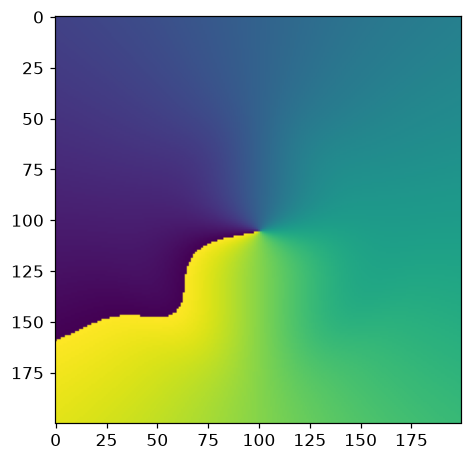

In [11]:
plt.imshow(np.angle(Ez))